### Experiments: BPE tokenizer for PAWS-Wiki

In [1]:
import os
import warnings

# Hide warnings (sklearn convergence, torch sparse tensors, etc.) to keep the outputs clean.
warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"


## 1. Training the tokenizer

Our classifier needs a way to segment text into tokens. We train a **Byte-Pair Encoding (BPE)** tokenizer on the PAWS training set.

BPE starts from single characters and repeatedly merges the most frequent pair of symbols until it reaches the target vocabulary size. Frequent words end up as a single token, while rare words (e.g. names) are split into sub-word pieces, so we almost never need an `[UNK]` token.

**Training data.** We use both sentences of every pair in the **train** split only (98,802 sentences), so no information from validation or test leaks into the tokenizer. PAWS is built from Wikipedia, so it is large enough for a vocabulary of this size.

In [2]:
from src.dataset import load_paws, tokenizer_corpus
from src.tokenization import train_tokenizer

dataset = load_paws()
corpus = tokenizer_corpus(dataset)   # train only, sentence1 + sentence2
print(f"{len(corpus):,} sentences in the tokenizer corpus")

Removed 63 examples from 31 conflicting pairs.
Training examples remaining: 49,338
98,676 sentences in the tokenizer corpus


## 2. Choosing the hyperparameters

Two hyperparameters:
- `vocab_size`: number of tokens in the vocabulary.
- `min_frequency`: a pair of symbols is only merged if it appears at least this many times.

We train several tokenizers and measure, on the **validation** sentences (unseen during training):
- `avg_tokens_per_sentence`: fewer tokens means the vocabulary groups more characters per token.
- `unk_rate`: fraction of tokens that are `[UNK]`. Close to 0 means the tokenizer covers new text.

Larger vocabularies give shorter sequences but sparser features, since many tokens appear only a few times.

In [3]:
import pandas as pd
from src.tokenization import tokenizer_stats

val_texts = list(dataset["validation"]["sentence1"]) + list(dataset["validation"]["sentence2"])

# Train each tokenizer once and keep it, so the following cells can reuse it
tokenizers = {}
rows = []
for vocab_size in [1000, 4000, 8000]:
    for min_freq in [2, 5]:
        tokenizers[(vocab_size, min_freq)] = train_tokenizer(corpus, vocab_size, min_freq)
        rows.append({"min_frequency": min_freq, **tokenizer_stats(tokenizers[(vocab_size, min_freq)], val_texts)})
pd.DataFrame(rows)

,min_frequency,vocab_size,avg_tokens_per_sentence,unk_rate
0,2,1000,44.898125,0.000063
1,5,1000,44.898125,0.000063
2,2,4000,33.070750,0.000085
3,5,4000,33.070750,0.000085
4,2,8000,29.212563,0.000096
5,5,8000,29.212563,0.000096


**Observations.**
- `min_frequency` has **no effect** here (2 and 5 give identical rows): with these vocabulary sizes every merge already appears far more than 5 times, so the filter never applies and training stops when `vocab_size` is reached. We keep `min_frequency=2`, as in the tutorial.
- `vocab_size` matters: going from 1,000 (the tutorial's value) to 4,000 shortens sentences considerably (≈45 → ≈33 tokens), and 8,000 gives a smaller further gain (≈29).
- `[UNK]` is practically zero in all cases (<0.02%), so coverage is not a differentiating factor.

These statistics only describe the tokenizers; they do not tell us which one classifies best. That is decided later with the classifier's validation accuracy.

### 2.1. Inspecting how sentences are tokenized

The table above averages over the whole validation set. To see *how* text is actually split, we look at three validation sentences with each vocabulary size. `▁` marks the start of a word. We look for: are frequent words kept whole? Are rare words (names) split into meaningful pieces or into single characters?

In [4]:
for i in [0, 5, 10]:
    sentence = dataset["validation"][i]["sentence1"]
    print(sentence)
    for vocab_size in [1000, 4000, 8000]:
        tokens = tokenizers[(vocab_size, 2)].encode(sentence).tokens
        print(f"  vocab={vocab_size:>5} ({len(tokens):>2} tokens): {' '.join(tokens)}")
    print()

Bradd Crellin represented BARLA Cumbria on a tour of Australia with 6 other players representing Britain , also on a tour of Australia .
  vocab= 1000 (48 tokens): ▁B rad d ▁C re l lin ▁rep resent ed ▁B A R L A ▁C um b ri a ▁on ▁a ▁t our ▁of ▁Austral ia ▁with ▁6 ▁other ▁play ers ▁rep resent ing ▁B rit ain ▁, ▁also ▁on ▁a ▁t our ▁of ▁Austral ia ▁.
  vocab= 4000 (35 tokens): ▁Brad d ▁C re l lin ▁represented ▁B A R L A ▁C umb ria ▁on ▁a ▁tour ▁of ▁Australia ▁with ▁6 ▁other ▁players ▁represent ing ▁Britain ▁, ▁also ▁on ▁a ▁tour ▁of ▁Australia ▁.
  vocab= 8000 (33 tokens): ▁Brad d ▁Cre l lin ▁represented ▁B A R LA ▁C umb ria ▁on ▁a ▁tour ▁of ▁Australia ▁with ▁6 ▁other ▁players ▁represent ing ▁Britain ▁, ▁also ▁on ▁a ▁tour ▁of ▁Australia ▁.

Kathy and her husband Pete Beale ( Peter Dean ) are stable financially .
  vocab= 1000 (30 tokens): ▁K ath y ▁and ▁her ▁h us b and ▁P et e ▁Be ale ▁( ▁P eter ▁De an ▁) ▁are ▁st able ▁f in an c ial ly ▁.
  vocab= 4000 (21 tokens): ▁Kath y ▁and ▁her ▁husba

**What to look for.** With a small vocabulary even common words are split (e.g. *husband*), which loses information; with a large one almost every word is a token, but many tokens are rare, so each has few training examples. Rare proper names are split in all cases.

## 3. Final tokenizer

In [5]:
# Final tokenizer: reuse the one already trained above (no need to train it again)
final_vocab_size = 8000   # change if the classifier comparison favours another size
tokenizer = tokenizers[(final_vocab_size, 2)]
tokenizer.save(f"tokenizer_bpe_{final_vocab_size}.json")
print("vocabulary size:", tokenizer.get_vocab_size())

vocabulary size: 8000


### 3.1. Example

A sentence from the validation set, split into BPE tokens. `▁` marks the start of a word. Frequent words stay whole, rare names are split into pieces.

In [6]:
example = dataset["validation"][0]["sentence1"]
print(example)
print(tokenizer.encode(example).tokens)

Bradd Crellin represented BARLA Cumbria on a tour of Australia with 6 other players representing Britain , also on a tour of Australia .
['▁Brad', 'd', '▁Cre', 'l', 'lin', '▁represented', '▁B', 'A', 'R', 'LA', '▁C', 'umb', 'ria', '▁on', '▁a', '▁tour', '▁of', '▁Australia', '▁with', '▁6', '▁other', '▁players', '▁represent', 'ing', '▁Britain', '▁,', '▁also', '▁on', '▁a', '▁tour', '▁of', '▁Australia', '▁.']


### Jaccard similarity analysis

The following code calculates the Jaccard similarity of the paraphrasing and non-paraphasing sentences of the dataset using an increasing group of tokens of them. After that, it calculates the mean value of the two distributions formed for every fixed group of tokens and substract them.

This allows us to analyze which is the optimal number of tokens we can group the sentences to obtain the maximum distinguishability between the paraphrasing and non-paraphrasing sentences, for later using it on the frequency N-gram enconder model. 


Analyzing BPE vocabulary: 8000


,vocab_size,n,mean_non_para,mean_para,mean_dist,cohens_d,pct_empty_pairs
0,8000,1,0.8597,0.8572,0.0025,0.0259,0.0000
1,8000,2,0.5533,0.6371,0.0839,0.5726,0.0000
2,8000,3,0.3847,0.5143,0.1295,0.8027,0.0000
3,8000,4,0.2752,0.4247,0.1495,0.8952,0.0000
4,8000,5,0.2023,0.3564,0.1541,0.9202,0.0000
5,8000,6,0.1521,0.3020,0.1500,0.9058,0.0000
6,8000,7,0.1164,0.2581,0.1417,0.8741,0.0041
7,8000,8,0.0903,0.2217,0.1314,0.8330,0.0081
8,8000,9,0.0706,0.1910,0.1204,0.7874,0.0263
9,8000,10,0.0555,0.1648,0.1093,0.7400,0.0993



Optimal n-gram size for each BPE vocabulary:


,vocab_size,best_n_mean_dist,best_mean_dist,best_n_cohens_d,best_cohens_d
0,8000,5,0.1541,5,0.9202


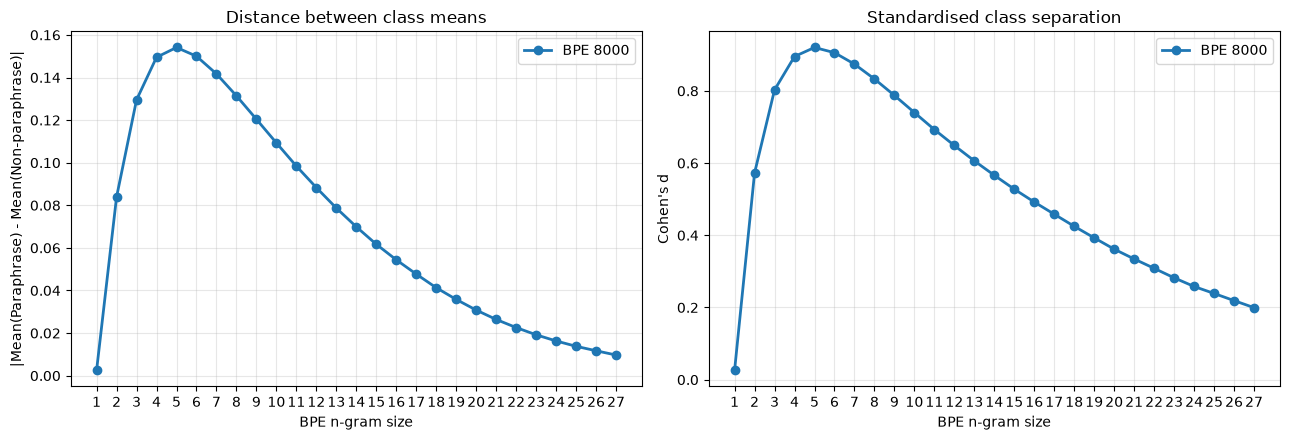

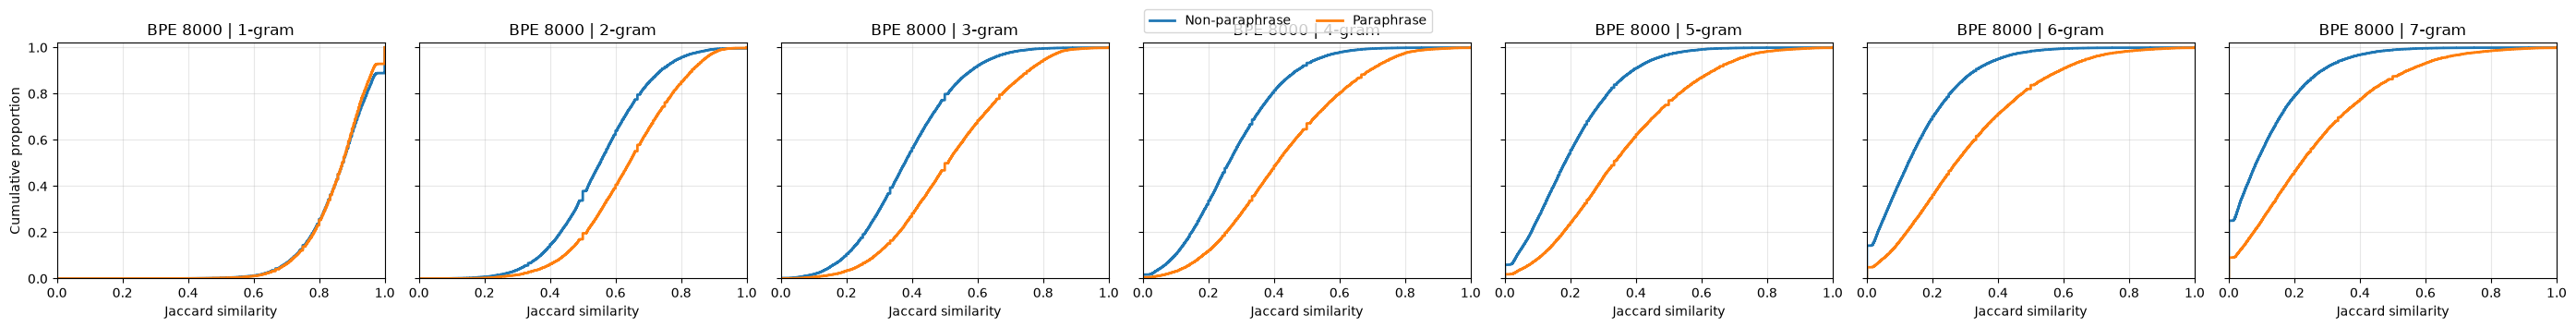

In [7]:
# ============================================================
# BPE-BASED JACCARD ANALYSIS
# Compare n-gram Jaccard across different BPE vocabulary sizes
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("images", exist_ok=True)   # the figures below are saved here

# -------------------- PARAMETERS --------------------

VOCAB_SIZES = [8000]
MIN_FREQ = 2
MAX_N = 27
MAX_PLOT_N = 7

# Use the original training split, as in data_exploration
train_df_bpe = dataset["train"].to_pandas()

labels = train_df_bpe["label"].to_numpy()

# -------------------- HELPER FUNCTIONS --------------------

def bpe_ngram_set(tokens, n):
    """Extract unique consecutive BPE n-grams."""
    return {
        tuple(tokens[i:i+n])
        for i in range(len(tokens) - n + 1)
    }


def bpe_jaccard(a, b):
    """Calculate Jaccard similarity between two sets."""
    union = len(a | b)
    return len(a & b) / union if union else 0.0


def cohens_d(x0, x1):
    """Calculate absolute Cohen's d using pooled standard deviation."""
    n0, n1 = len(x0), len(x1)

    pooled_std = np.sqrt(
        (
            (n0 - 1) * x0.var(ddof=1)
            + (n1 - 1) * x1.var(ddof=1)
        ) / (n0 + n1 - 2)
    )

    return abs(x1.mean() - x0.mean()) / pooled_std if pooled_std > 0 else 0.0


# -------------------- MAIN ANALYSIS --------------------

bpe_results = {}
summary_rows = []

for vocab_size in VOCAB_SIZES:

    print(f"\nAnalyzing BPE vocabulary: {vocab_size}")

    # Retrieve the previously trained tokenizer
    bpe_tokenizer = tokenizers[(vocab_size, MIN_FREQ)]

    # Tokenize both sentences using BPE
    tokens1 = [
        bpe_tokenizer.encode(text).tokens
        for text in train_df_bpe["sentence1"]
    ]

    tokens2 = [
        bpe_tokenizer.encode(text).tokens
        for text in train_df_bpe["sentence2"]
    ]

    results_by_n = {}

    for n in range(1, MAX_N + 1):

        # Generate BPE n-gram sets
        sets1 = [bpe_ngram_set(t, n) for t in tokens1]
        sets2 = [bpe_ngram_set(t, n) for t in tokens2]

        # Calculate Jaccard for every sentence pair
        jac = np.array([
            bpe_jaccard(a, b)
            for a, b in zip(sets1, sets2)
        ])

        # Separate classes
        j0 = jac[labels == 0]
        j1 = jac[labels == 1]

        mean_dist = abs(j1.mean() - j0.mean())

        # Store results
        results_by_n[n] = jac

        summary_rows.append({
            "vocab_size": vocab_size,
            "n": n,
            "mean_non_para": j0.mean(),
            "mean_para": j1.mean(),
            "mean_dist": mean_dist,
            "cohens_d": cohens_d(j0, j1),
            "pct_empty_pairs": 100 * np.mean([
                not (a or b)
                for a, b in zip(sets1, sets2)
            ])
        })

    bpe_results[vocab_size] = results_by_n


# -------------------- RESULTS TABLE --------------------

bpe_summary = pd.DataFrame(summary_rows).round(4)

display(bpe_summary)


# -------------------- OPTIMAL N FOR EACH VOCABULARY --------------------

optimal_rows = []

for vocab_size in VOCAB_SIZES:

    subset = bpe_summary[
        bpe_summary["vocab_size"] == vocab_size
    ]

    best_dist = subset.loc[subset["mean_dist"].idxmax()]
    best_d = subset.loc[subset["cohens_d"].idxmax()]

    optimal_rows.append({
        "vocab_size": vocab_size,
        "best_n_mean_dist": int(best_dist["n"]),
        "best_mean_dist": best_dist["mean_dist"],
        "best_n_cohens_d": int(best_d["n"]),
        "best_cohens_d": best_d["cohens_d"]
    })

optimal_summary = pd.DataFrame(optimal_rows).round(4)

print("\nOptimal n-gram size for each BPE vocabulary:")
display(optimal_summary)


# -------------------- PLOT 1: METRIC COMPARISON --------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.5)
)

for vocab_size in VOCAB_SIZES:

    subset = bpe_summary[
        bpe_summary["vocab_size"] == vocab_size
    ]

    axes[0].plot(
        subset["n"],
        subset["mean_dist"],
        marker="o",
        linewidth=2,
        label=f"BPE {vocab_size}"
    )

    axes[1].plot(
        subset["n"],
        subset["cohens_d"],
        marker="o",
        linewidth=2,
        label=f"BPE {vocab_size}"
    )

axes[0].set_title("Distance between class means")
axes[0].set_xlabel("BPE n-gram size")
axes[0].set_ylabel(
    "|Mean(Paraphrase) - Mean(Non-paraphrase)|"
)

axes[1].set_title("Standardised class separation")
axes[1].set_xlabel("BPE n-gram size")
axes[1].set_ylabel("Cohen's d")

for ax in axes:
    ax.set_xticks(range(1, MAX_N + 1))
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig("images/bpe_jaccard_metrics.png", dpi=300, bbox_inches="tight")
plt.show()


# -------------------- PLOT 2: CUMULATIVE DISTRIBUTIONS --------------------

fig, axes = plt.subplots(
    len(VOCAB_SIZES),
    MAX_PLOT_N,
    figsize=(4 * MAX_PLOT_N, 3.5 * len(VOCAB_SIZES)),
    sharex=True,
    sharey=True,
    squeeze=False
)

for row, vocab_size in enumerate(VOCAB_SIZES):

    for col, n in enumerate(range(1, MAX_PLOT_N + 1)):

        ax = axes[row, col]
        jac = bpe_results[vocab_size][n]

        for label, name in [
            (0, "Non-paraphrase"),
            (1, "Paraphrase")
        ]:

            values = np.sort(jac[labels == label])
            cumulative = np.arange(1, len(values) + 1) / len(values)

            # Anchor curves at (0,0) and (1,1)
            values = np.r_[0, values, 1]
            cumulative = np.r_[0, cumulative, 1]

            ax.step(
                values,
                cumulative,
                where="post",
                linewidth=2,
                label=name
            )

        ax.set_title(f"BPE {vocab_size} | {n}-gram")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.02)
        ax.grid(alpha=0.3)

        if col == 0:
            ax.set_ylabel("Cumulative proportion")

        if row == len(VOCAB_SIZES) - 1:
            ax.set_xlabel("Jaccard similarity")

# One shared legend
handles, legend_labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    legend_labels,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 1.02)
)

plt.tight_layout()
plt.savefig(
    "images/bpe_jaccard_cumulative.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## 4. Representation spaces

An encoder maps one input to a vector. For a pair we encode each sentence with a base encoder and concatenate the two vectors (`PairEncoder`):

| Name | Base encoder (per sentence) |
|---|---|
| `TokenIndicator` | 1 if the token appears in the sentence, else 0 |
| `BagOfWords` | number of times each token appears in the sentence |
| `Frequency Ngram` | number of times each N-group of token appears in the sentence |

In [8]:
from collections import OrderedDict
from src.encoders import TokenIndicator, BagOfWords, PairEncoder, NgramBagOfWords

encoders = {
    "NGram": PairEncoder(NgramBagOfWords(tokenizer, n = 5, include_lower=False).fit(corpus)),
    "TokenIndicator": PairEncoder(TokenIndicator(tokenizer)),
    "BagOfWords":  PairEncoder(BagOfWords(tokenizer)),
}

encoders_concat = {
    "NGram": PairEncoder(NgramBagOfWords(tokenizer, n = 5, include_lower=False).fit(corpus), mode="concat"),
    "TokenIndicator": PairEncoder(TokenIndicator(tokenizer), mode="concat"),
    "BagOfWords":     PairEncoder(BagOfWords(tokenizer), mode="concat"),
}


## 5. Cross-validation setup

Each PAWS example is a **pair** of sentences, so an input `x` is the tuple `(sentence1, sentence2)`. The code from the tutorial works with `(input, label)` pairs, so we build them in that format.

We run 5-fold cross-validation on the **train** split. A random split would be wrong for PAWS: the same sentence appears in several pairs (often with opposite labels), so most validation pairs would contain a sentence already seen in training (95.6% in our data), and a model that memorizes sentences would be rewarded or punished for it. Instead, **pairs that share a sentence (directly or through other pairs) are always placed in the same fold**, so no validation sentence is seen in training. The seed makes the split reproducible, and all models use exactly the same folds so that the comparison is fair. The validation and test splits of PAWS are left untouched.

In [9]:
from src import experiment, clslib, analysis
from src.dataset import paws_pairs

outcome_space = clslib.NamedClasses(["different meaning", "paraphrase"])
results_folder = "results"

my_seeds = [0]
num_folds = 5
my_cross_validation_sets = [
    experiment.cross_validation_split(paws_pairs(dataset["train"]), k=num_folds, seed=seed)
    for seed in my_seeds
]

In [10]:
# Sanity check: no sentence of a validation fold appears in the training folds
for f, split in my_cross_validation_sets[0].items():
    train_sentences = {s for (s1, s2), _ in split["training"] for s in (s1, s2)}
    leaked = sum(s1 in train_sentences or s2 in train_sentences for (s1, s2), _ in split["validation"])
    print(f"fold {f}: {leaked} of {len(split['validation'])} validation pairs share a sentence with training")

fold 0: 0 of 9868 validation pairs share a sentence with training
fold 1: 0 of 9868 validation pairs share a sentence with training
fold 2: 0 of 9868 validation pairs share a sentence with training
fold 3: 0 of 9867 validation pairs share a sentence with training
fold 4: 0 of 9867 validation pairs share a sentence with training


## 6. Logistic regression (log-linear model)

We train one logistic regression per representation space and per fold, and record the accuracy on the held-out fold.

### 6.1. Tuning the logistic regression

The regularization strength is controlled by `C` (smaller `C` = stronger regularization). With thousands of features and weak signal, a stronger penalty may reduce overfitting. We train the same model with several values of `C`, for every representation and on the same folds, and keep each one as a separate system so they can be compared later (`logistic_<encoder>` above is `C=1`).

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

logistic_NGram_C0.001               0.5583
logistic_NGram_C0.01                0.5639
logistic_NGram_C0.1                 0.5686
logistic_NGram_C1                   0.5695
logistic_TokenIndicator_C0.001      0.5619
logistic_TokenIndicator_C0.01       0.5689
logistic_TokenIndicator_C0.1        0.5534
logistic_TokenIndicator_C1          0.5381
logistic_BagOfWords_C0.001          0.5692
logistic_BagOfWords_C0.01           0.5676
logistic_BagOfWords_C0.1            0.5630
logistic_BagOfWords_C1              0.5626


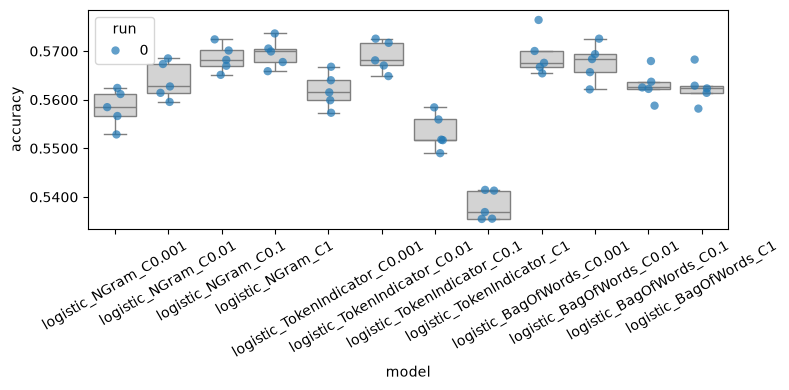

In [11]:
C_values = [0.001, 0.01, 0.1, 1]          # C=1 is the run above

my_classifiers = OrderedDict()
for enc_name, enc in encoders.items():
    for C in C_values:
        name = f"logistic_{enc_name}_C{C}"
        my_classifiers[name] = [
            experiment.cross_validation_experiment(
                data_splits=my_cross_validation_sets[run],
                outcome_space=outcome_space,
                encoder=enc,
                model_option="logistic",
                save_to=f"{results_folder}/{name}/seed-{seed}",
                loglin_args={"max_iter": 100, "C": C},
            )
            for run, seed in enumerate(my_seeds)
        ]

# mean accuracy over folds for every logistic system
for name, runs in my_classifiers.items():
    if name.startswith("logistic"):
        accs = [a for r in runs for a in r["accuracies"].values()]
        print(f"{name:35s} {sum(accs)/len(accs):.4f}")

df_all = analysis.make_data_frame(my_classifiers)
from src.figures import saving_figure, save_table, save_figure
with saving_figure("images/logistic_accuracies.png"):
    analysis.plot_box_and_points(df_all[df_all["model"].str.startswith("logistic")])

# Save the results so they survive a kernel restart (section 9 can reload them without retraining)
import pickle
with open(f"{results_folder}/my_classifiers.pkl", "wb") as f:
    pickle.dump(my_classifiers, f)

## 7. MLP (one hidden layer)

Same experiment, replacing the logistic regression with a neural network with one hidden layer (128 units, ReLU, dropout 0.1).

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 19.623 seconds
Dataloader done! Time taken: 0.005 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6868 | train acc: 0.5620 | val loss: 0.6834 | val acc: 0.5671
Epoch 02 | train loss: 0.6761 | train acc: 0.5816 | val loss: 0.6806 | val acc: 0.5698
Epoch 03 | train loss: 0.6658 | train acc: 0.5916 | val loss: 0.6795 | val acc: 0.5694
Epoch 04 | train loss: 0.6577 | train acc: 0.5971 | val loss: 0.6787 | val acc: 0.5705
Epoch 05 | train loss: 0.6522 | train acc: 0.5985 | val loss: 0.6783 | val acc: 0.5707
Epoch 06 | train loss: 0.6485 | train acc: 0.5997 | val loss: 0.6787 | val acc: 0.5665
Epoch 07 | train loss: 0.6455 | train acc: 0.6006 | val loss: 0.6791 | val acc: 0.5659
Epoch 08 | train loss: 0.6433 | train acc: 0.6008 | val loss: 0.6805 | val acc: 0.5583
Epoch 09 | train loss: 0.6414 | train acc: 0.6014 | val loss: 0.6803 | val acc: 0.5618
Epoch 10 | train loss: 0.6400 | train acc: 0.6019 | val loss: 0.6815 | val acc: 0.5575
Training done! Time taken: 865.739 seconds
Transforming documents...
Document transformation done! Time taken: 36.504 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6870 | train acc: 0.5576 | val loss: 0.6839 | val acc: 0.5619
Epoch 02 | train loss: 0.6759 | train acc: 0.5832 | val loss: 0.6806 | val acc: 0.5641
Epoch 03 | train loss: 0.6666 | train acc: 0.5918 | val loss: 0.6786 | val acc: 0.5687
Epoch 04 | train loss: 0.6591 | train acc: 0.5967 | val loss: 0.6779 | val acc: 0.5643
Epoch 05 | train loss: 0.6536 | train acc: 0.5987 | val loss: 0.6778 | val acc: 0.5634
Epoch 06 | train loss: 0.6498 | train acc: 0.5999 | val loss: 0.6768 | val acc: 0.5650
Epoch 07 | train loss: 0.6469 | train acc: 0.6001 | val loss: 0.6777 | val acc: 0.5589
Epoch 08 | train loss: 0.6446 | train acc: 0.6008 | val loss: 0.6773 | val acc: 0.5596
Epoch 09 | train loss: 0.6428 | train acc: 0.6007 | val loss: 0.6782 | val acc: 0.5537
Epoch 10 | train loss: 0.6413 | train acc: 0.6023 | val loss: 0.6791 | val acc: 0.5499
Training done! Time taken: 501.733 seconds
Transforming documents...
Document transformation done! Time taken: 27.043 seconds
Data

... (26 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6839 | train acc: 0.5702 | val loss: 0.6809 | val acc: 0.5666
Epoch 02 | train loss: 0.6720 | train acc: 0.5988 | val loss: 0.6791 | val acc: 0.5716
Epoch 03 | train loss: 0.6594 | train acc: 0.6134 | val loss: 0.6793 | val acc: 0.5730
Epoch 04 | train loss: 0.6481 | train acc: 0.6166 | val loss: 0.6806 | val acc: 0.5722
Epoch 05 | train loss: 0.6391 | train acc: 0.6192 | val loss: 0.6827 | val acc: 0.5669
Epoch 06 | train loss: 0.6321 | train acc: 0.6213 | val loss: 0.6860 | val acc: 0.5643
Epoch 07 | train loss: 0.6264 | train acc: 0.6217 | val loss: 0.6876 | val acc: 0.5622
Epoch 08 | train loss: 0.6218 | train acc: 0.6214 | val loss: 0.6907 | val acc: 0.5606
Epoch 09 | train loss: 0.6173 | train acc: 0.6230 | val loss: 0.6940 | val acc: 0.5600
Epoch 10 | train loss: 0.6133 | train acc: 0.6235 | val loss: 0.6974 | val acc: 0.5574
Training done! Time taken: 439.694 seconds
Transforming documents...
Document transformation done! Time taken: 20.254 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6860 | train acc: 0.5696 | val loss: 0.6816 | val acc: 0.5635
Epoch 02 | train loss: 0.6728 | train acc: 0.6023 | val loss: 0.6786 | val acc: 0.5707
Epoch 03 | train loss: 0.6610 | train acc: 0.6105 | val loss: 0.6769 | val acc: 0.5732
Epoch 04 | train loss: 0.6502 | train acc: 0.6151 | val loss: 0.6754 | val acc: 0.5710
Epoch 05 | train loss: 0.6418 | train acc: 0.6153 | val loss: 0.6768 | val acc: 0.5698
Epoch 06 | train loss: 0.6349 | train acc: 0.6178 | val loss: 0.6779 | val acc: 0.5694
Epoch 07 | train loss: 0.6291 | train acc: 0.6194 | val loss: 0.6801 | val acc: 0.5673
Epoch 08 | train loss: 0.6246 | train acc: 0.6191 | val loss: 0.6818 | val acc: 0.5694
Epoch 09 | train loss: 0.6203 | train acc: 0.6224 | val loss: 0.6834 | val acc: 0.5648
Epoch 10 | train loss: 0.6164 | train acc: 0.6222 | val loss: 0.6858 | val acc: 0.5657
Training done! Time taken: 533.277 seconds


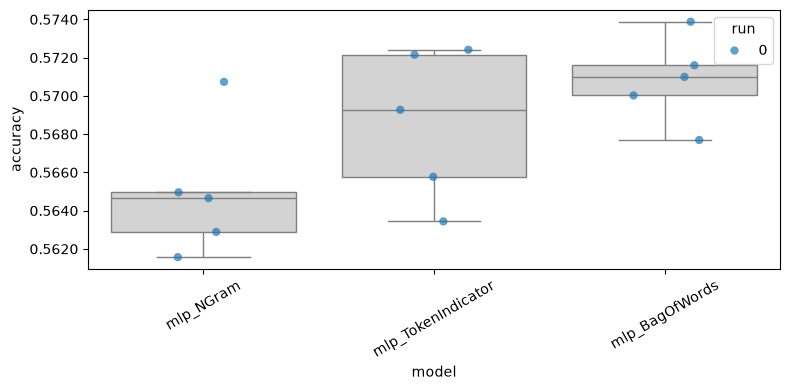

In [14]:
mlp_args = {"hidden_dim": 128, "dropout": 0.1, "batch_size": 64,
            "learning_rate": 1e-4, "weight_decay": 1e-4, "num_epochs": 10}

for enc_name, enc in encoders.items():
    name = f"mlp_{enc_name}"
    if name in my_classifiers:
        continue
    my_classifiers[name] = [
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=enc,
            model_option="mlp",
            save_to=f"{results_folder}/{name}/seed-{seed}",
            smlp_args=mlp_args,
        )
        for run, seed in enumerate(my_seeds)
    ]

df_all = analysis.make_data_frame(my_classifiers)
from src.figures import saving_figure, save_table, save_figure
with saving_figure("images/mlp_accuracies.png"):
    analysis.plot_box_and_points(df_all[df_all["model"].str.startswith("mlp")])

# Save the results so they survive a kernel restart (section 9 can reload them without retraining)
import pickle
with open(f"{results_folder}/my_classifiers.pkl", "wb") as f:
    pickle.dump(my_classifiers, f)

### 7.1. Choosing the MLP hyperparameters

The training log of the basic MLP shows overfitting: training accuracy keeps rising while the validation loss gets worse after the first epochs. We look for hyperparameter changes that reduce it, **one change at a time** with respect to the basic MLP so that we know which one is responsible for an improvement:
- `dropout` 0.1 -> 0.5 and `weight_decay` 1e-4 -> 1e-3: stronger regularization.
- `hidden_dim` 128 -> 64: fewer parameters to memorize the training set.
- `learning_rate` 1e-4 -> 1e-3: in case it simply learns too slowly.

All variants use the same 5 folds, one representation (`BagOfWords`) to limit the cost, 3 epochs (the best epoch is among the first ones), and are compared by the mean validation accuracy only. The test set is not used to choose hyperparameters.

In [ ]:
import numpy as np
import pandas as pd

tune_encoder = "BagOfWords"
search_epochs = 3     # same number of epochs for ALL the variants, including the reference

variants = {
    "basic":      {**mlp_args, "num_epochs": search_epochs},                        # reference
    "dropout0.5": {**mlp_args, "num_epochs": search_epochs, "dropout": 0.5},
    "wd1e-3":     {**mlp_args, "num_epochs": search_epochs, "weight_decay": 1e-3},
    "hidden64":   {**mlp_args, "num_epochs": search_epochs, "hidden_dim": 64},
    "lr1e-3":     {**mlp_args, "num_epochs": search_epochs, "learning_rate": 1e-3},
}

tuning_results = {}
for tag, args in variants.items():
    name = f"tune_{tune_encoder}_{tag}"
    if name in tuning_results:
        continue
    tuning_results[tag] = experiment.cross_validation_experiment(
        data_splits=my_cross_validation_sets[0],
        outcome_space=outcome_space,
        encoder=encoders[tune_encoder],
        model_option="mlp",
        save_to=f"{results_folder}/{name}/seed-{my_seeds[0]}",
        smlp_args=args,
    )
    # save progress after each variant, so a crash doesn't lose everything
    with open(f"{results_folder}/tuning_results.pkl", "wb") as f:
        pickle.dump(tuning_results, f)

base_accs = list(tuning_results["basic"]["accuracies"].values())
rows = []
for tag, res in tuning_results.items():
    accs = list(res["accuracies"].values())
    rows.append({"config": tag, "mean acc": np.mean(accs), "std": np.std(accs),
                 "diff vs basic": np.mean(accs) - np.mean(base_accs)})
from src.figures import save_table
table = save_table(pd.DataFrame(rows).round(4), "tables/mlp_hyperparameter_search.csv")
table


### 7.2. MLP with tuned hyperparameters

We train the one-hidden-layer MLP with the changes that improved the mean accuracy in section 7.1, for the two representations that did best with the logistic regression. **Edit `mlp_tuned_args` below to keep only the changes that helped**; the values shown are the candidates.

In [ ]:
mlp_tuned_args = {**mlp_args, "dropout": 0.5, "weight_decay": 1e-3, "hidden_dim": 64}   # keep only what helped in 7.1
tuned_encoders = ["BagOfWords", "NGram"]

for enc_name in tuned_encoders:
    name = f"mlp_tuned_{enc_name}"
    if name in my_classifiers:
        continue
    my_classifiers[name] = [
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=encoders[enc_name],
            model_option="mlp",
            save_to=f"{results_folder}/{name}/seed-{seed}",
            smlp_args=mlp_tuned_args,
        )
        for run, seed in enumerate(my_seeds)
    ]

df_all = analysis.make_data_frame(my_classifiers)
from src.figures import saving_figure, save_table, save_figure
with saving_figure("images/mlp_tuned_accuracies.png"):
    analysis.plot_box_and_points(df_all[df_all["model"].str.startswith("mlp")])

# Save the results so they survive a kernel restart (section 9 can reload them without retraining)
import pickle
with open(f"{results_folder}/my_classifiers.pkl", "wb") as f:
    pickle.dump(my_classifiers, f)

## 8. MLP with more hidden layers (extra architecture)

The assignment asks for one architecture of our choice besides the log-linear model and the one-hidden-layer MLP. We extend the MLP with **additional hidden layers**. The first layer still takes the sparse input; every extra layer is dense (`hidden_dim -> hidden_dim`, ReLU, dropout). With `num_hidden_layers=1` the model is exactly the tutorial's MLP.

**Motivation.** A deeper network can combine the token-level features into higher-level ones, which in principle could help to capture interactions between tokens of the two sentences that a single hidden layer misses.

**What we vary.** The regularization (`dropout`, `weight_decay`) is fixed to the values chosen for the tuned one-hidden-layer MLP (section 7.2), so that the only difference between both models is the structure. We try the number of layers (2 or 3) and the hidden width (64 or 128).

We follow the same protocol as before: the same 5 folds, one representation (`BagOfWords`) to choose the structure, 3 epochs, and selection by mean validation accuracy only. The test set is not used.


In [ ]:
import numpy as np

tune_encoder = "BagOfWords"

structure_variants = {
    "L2_h64":  {**mlp_tuned_args, "num_hidden_layers": 2, "hidden_dim": 64},
    "L3_h64":  {**mlp_tuned_args, "num_hidden_layers": 3, "hidden_dim": 64},
    "L2_h128": {**mlp_tuned_args, "num_hidden_layers": 2, "hidden_dim": 128},
}

# reference: the tuned one-hidden-layer MLP (same folds)
ref_accs = list(my_classifiers[f"mlp_tuned_{tune_encoder}"][0]["accuracies"].values())

structure_results = {}
for tag, args in structure_variants.items():
    name = f"structure_{tune_encoder}_{tag}"
    structure_results[tag] = experiment.cross_validation_experiment(
        data_splits=my_cross_validation_sets[0],
        outcome_space=outcome_space,
        encoder=encoders[tune_encoder],
        model_option="mlp",
        save_to=f"{results_folder}/{name}/seed-{my_seeds[0]}",
        smlp_args=args,
    )

rows = [{"config": "tuned MLP (1 layer)", "mean acc": np.mean(ref_accs), "std": np.std(ref_accs)}]
for tag, res in structure_results.items():
    accs = list(res["accuracies"].values())
    rows.append({"config": tag, "mean acc": np.mean(accs), "std": np.std(accs),
                 "diff vs tuned MLP": np.mean(accs) - np.mean(ref_accs)})
from src.figures import saving_figure, save_table, save_figure
table = save_table(pd.DataFrame(rows).round(4), "tables/mlp_structure_search.csv")
table


### 8.1. Final deeper MLP

We train the best structure from the table above for both representations, with the same hyperparameters as the tuned one-hidden-layer MLP. **Edit `mlp_2layers_args` to the winning structure** (number of layers and width).

In [ ]:
mlp_2layers_args = {**mlp_tuned_args, "num_hidden_layers": 2}   # use the winning structure of the table above

for enc_name in tuned_encoders:
    name = f"mlp_2layers_{enc_name}"
    if name in my_classifiers:
        continue
    my_classifiers[name] = [
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=encoders[enc_name],
            model_option="mlp",
            save_to=f"{results_folder}/{name}/seed-{seed}",
            smlp_args=mlp_2layers_args,
        )
        for run, seed in enumerate(my_seeds)
    ]

df_all = analysis.make_data_frame(my_classifiers)
from src.figures import saving_figure, save_table, save_figure
with saving_figure("images/mlp_2layers_accuracies.png"):
    analysis.plot_box_and_points(df_all[df_all["model"].str.startswith("mlp")])

# Save the results so they survive a kernel restart (section 9 can reload them without retraining)
import pickle
with open(f"{results_folder}/my_classifiers.pkl", "wb") as f:
    pickle.dump(my_classifiers, f)

## 9. Evaluation analysis

All systems are evaluated on the same 5 cross-validation folds (the test set is not used here). The analysis has three parts:
1. a **summary table** with every system, plus a reference that always predicts the majority class;
2. a Bayesian comparison of **the best system of each family**;
3. **planned comparisons** that answer the questions of the project: does the architecture matter? does the representation matter? does the best system beat the majority class?

The comparison uses a Bayesian correlated t-test on the per-fold accuracies with a **ROPE of 1 accuracy point**: differences smaller than that are treated as a tie.

### 9.0. Loading the saved results

The training sections save `my_classifiers` to disk after every block. If the kernel was restarted, this cell recovers them, so that sections 9.1-9.3 can be run **without training anything again**. If `my_classifiers` is already in memory, it is used as it is.

In [ ]:
import pickle
from src import experiment, clslib, analysis
from src.dataset import load_paws, paws_pairs

results_folder = "results"
num_folds = 5
my_seeds = [0]

if "dataset" not in globals():
    dataset = load_paws()
if "my_cross_validation_sets" not in globals():      # same seed -> exactly the same folds as in the training
    my_cross_validation_sets = [
        experiment.cross_validation_split(paws_pairs(dataset["train"]), k=num_folds, seed=seed) for seed in my_seeds
    ]
if "outcome_space" not in globals():
    outcome_space = clslib.NamedClasses(["different meaning", "paraphrase"])
if "my_classifiers" not in globals():
    with open(f"{results_folder}/my_classifiers.pkl", "rb") as f:
        my_classifiers = pickle.load(f)
    print("Loaded the saved results:", len(my_classifiers), "systems")

### 9.1. Summary of all systems

Mean accuracy and standard deviation over the 5 folds, for every system. `majority_class` is the accuracy of always predicting the most frequent class of the fold: a system that does not clearly beat it has learned nothing useful.

In [ ]:
import numpy as np
from src.bayes_rope import scores_by_model

df   = analysis.make_data_frame(my_classifiers)
wide = scores_by_model(df, fold_col="fold")       # one row per (run, fold), one column per system

# Reference: always predict the majority class of the validation fold
majority = {}
for r, folds in enumerate(my_cross_validation_sets):
    for f, split in folds.items():
        p = np.mean([label for _, label in split["validation"]])
        majority[(r, f)] = max(p, 1 - p)
wide["majority_class"] = [majority[idx] for idx in wide.index]

ROPE = 0.01                                       # 1 accuracy point

summary = wide.agg(["mean", "std"]).T.sort_values("mean", ascending=False)
summary.columns = ["mean accuracy", "std over folds"]
from src.figures import saving_figure, save_table, save_figure
display(save_table(summary.round(4), "tables/summary_all_systems.csv"))

### 9.2. Best system of each family

To keep the number of comparisons manageable, we compare the system with the highest mean accuracy of each family (logistic regression, MLP, tuned MLP, deeper MLP) and the majority-class reference.

In [ ]:
from src.bayes_rope import compare_models, plot_posteriors

# Best system (highest mean accuracy) of each family
families = {
    "logistic":    [c for c in wide.columns if c.startswith("logistic_")],
    "mlp":         [c for c in wide.columns if c in ("mlp_TokenIndicator", "mlp_BagOfWords", "mlp_NGram")],
    "mlp_tuned":   [c for c in wide.columns if c.startswith("mlp_tuned_")],
    "mlp_2layers": [c for c in wide.columns if c.startswith("mlp_2layers_")],
}
best = [wide[cols].mean().idxmax() for cols in families.values() if cols] + ["majority_class"]
print("Systems compared:", best)

tabla, posts = compare_models(wide, k=num_folds, rope=ROPE, models=best)
from src.figures import saving_figure, save_table, save_figure
display(save_table(tabla.round(3), "tables/rope_best_of_each_family.csv"))
save_figure(plot_posteriors(posts, ROPE), "images/rope_best_of_each_family.png");

### 9.3. Planned comparisons

Instead of comparing everything with everything, we compare the pairs that answer the questions of the project. In every pair, A is the first system and the difference is `A - B`:
- **Architecture** (fixed representation, the one of the best system): logistic regression vs. MLP, MLP vs. tuned MLP, tuned MLP vs. deeper MLP.
- **Representation** (fixed architecture): `NGram` vs. `BagOfWords` and vs. `TokenIndicator`, and `BagOfWords` vs. `TokenIndicator`, for the logistic regression (best `C` of each) and for the basic MLP.
- **Baseline:** the best system vs. always predicting the majority class.

In [ ]:
def system(arch, enc):
    """Column of `wide` for an architecture and an encoder (for the logistic regression, its best C). None if it was not trained."""
    if arch == "logistic":
        cols = [c for c in wide.columns if c.startswith(f"logistic_{enc}_C")]
        return wide[cols].mean().idxmax() if cols else None
    name = f"{arch}_{enc}"
    return name if name in wide.columns else None

all_systems = wide.drop(columns="majority_class")
best_overall = all_systems.mean().idxmax()
best_enc = [e for e in ("NGram", "BagOfWords", "TokenIndicator") if e in best_overall][0]
print(f"Best system: {best_overall} (mean accuracy {all_systems[best_overall].mean():.4f}); encoder used for the architecture comparisons: {best_enc}")

planned = []   # (question, A, B)
for a, b in [("logistic", "mlp"), ("mlp", "mlp_tuned"), ("mlp_tuned", "mlp_2layers")]:
    planned.append((f"architecture ({best_enc})", system(a, best_enc), system(b, best_enc)))
for arch in ["logistic", "mlp"]:
    for ea, eb in [("NGram", "BagOfWords"), ("NGram", "TokenIndicator"), ("BagOfWords", "TokenIndicator")]:
        planned.append((f"representation ({arch})", system(arch, ea), system(arch, eb)))
planned.append(("baseline", best_overall, "majority_class"))

planned = [(q, a, b) for q, a, b in planned if a is not None and b is not None]
tabla_planned, posts_planned = compare_models(wide, k=num_folds, rope=ROPE, pairs=[(a, b) for q, a, b in planned])
tabla_planned.insert(0, "question", [q for q, a, b in planned])
from src.figures import saving_figure, save_table, save_figure
display(save_table(tabla_planned.round(3), "tables/rope_planned_comparisons.csv"))
save_figure(plot_posteriors(posts_planned, ROPE), "images/rope_planned_comparisons.png");

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, f1_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from src.figures import saving_figure, save_table, save_figure

def cv_predictions(name, run=0):
    """Gold labels and predictions of all validation folds of a system, in the same order."""
    folds = my_cross_validation_sets[run]
    result = my_classifiers[name][run]
    y_true = np.concatenate([[label for x, label in folds[f]["validation"]] for f in folds])
    y_pred = np.concatenate([np.asarray(result["predictions"][f]) for f in folds])
    return y_true, y_pred

# System with the highest mean validation accuracy (change it to analyse another one)
best_system = max(my_classifiers, key=lambda n: np.mean(list(my_classifiers[n][0]["accuracies"].values())))
y_true, y_pred = cv_predictions(best_system)

print(f"System: {best_system} (predictions on the cross-validation validation folds)\n")
print("Confusion matrix (rows = gold, columns = predicted):")
print(confusion_matrix(y_true, y_pred))
print("\n", classification_report(y_true, y_pred, target_names=list(outcome_space)))
print("Macro F1:", round(f1_score(y_true, y_pred, average="macro"), 4))

disp = ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=list(outcome_space), cmap="Blues", colorbar=False)
disp.ax_.set_title(f"{best_system} (cross-validation folds)")
save_figure(disp.figure_, "images/confusion_matrix_cv.png");

## 10. Final evaluation on the test set

Everything above used the cross-validation folds of the **train** split. Now we take **one** system, the best one according to section 9, retrain it on the whole train split and evaluate it on the PAWS **test** split, which has not been used for any decision. For the MLP, the official validation split is used only to choose the epoch (lowest validation loss). The test set is evaluated once.

We checked that neither the validation nor the test split share any sentence with the train split (0 of 8,000 pairs in both), so the test evaluation does not suffer from the leakage that a random cross-validation has.

In [ ]:
import numpy as np
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report, f1_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from src.figures import saving_figure, save_table, save_figure
from src import loglin, smlp

def parse_system(name):
    """System name -> (architecture, encoder name, training arguments)."""
    if name.startswith("logistic_"):
        enc, C = name[len("logistic_"):].rsplit("_C", 1)
        return "logistic", enc, {"C": float(C)}
    for arch, args in [("mlp_tuned", mlp_tuned_args), ("mlp_2layers", mlp_2layers_args), ("mlp", mlp_args)]:
        if name.startswith(arch + "_"):
            return arch, name[len(arch) + 1:], args
    raise ValueError(f"Unknown system {name}")

final_system = best_overall          # chosen in section 9
arch, enc_name, args = parse_system(final_system)
print(f"Final system: {final_system}  (architecture={arch}, encoder={enc_name})")

train_pairs = paws_pairs(dataset["train"])
val_pairs   = paws_pairs(dataset["validation"])
test_pairs  = paws_pairs(dataset["test"])
test_x      = [x for x, _ in test_pairs]
y_test      = np.array([label for _, label in test_pairs])

encoder = encoders[enc_name]
final_folder = Path(f"{results_folder}/final_{final_system}")
final_folder.mkdir(parents=True, exist_ok=True)
save_to = f"{final_folder}/model"

if arch == "logistic":
    model = loglin.fit(train_pairs, encoder, save_to=save_to, max_iter=100, C=args["C"])
    y_pred = np.asarray(loglin.predict(test_x, model, encoder))
else:
    smlp.train_neural_network_model(train_pairs, val_pairs, len(outcome_space), encoder, save_to=save_to, **args)
    model = smlp.load(save_to)
    y_pred = smlp.predict_probs(test_x, model, encoder, batch_size=256).argmax(axis=1)

majority_acc = max(y_test.mean(), 1 - y_test.mean())
print(f"\nTest accuracy: {(y_pred == y_test).mean():.4f}   (always predicting the majority class: {majority_acc:.4f})")
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))
print("\nConfusion matrix (rows = gold, columns = predicted):")
print(confusion_matrix(y_test, y_pred))
print("\n", classification_report(y_test, y_pred, target_names=list(outcome_space)))

report = classification_report(y_test, y_pred, target_names=list(outcome_space))
with open("tables/test_report.txt", "w", encoding="utf-8") as f:
    f.write(f"System: {final_system}\nTest accuracy: {(y_pred == y_test).mean():.4f} (majority class: {majority_acc:.4f})\n"
            f"Macro F1: {f1_score(y_test, y_pred, average='macro'):.4f}\n\n{report}")
disp = ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=list(outcome_space), cmap="Blues", colorbar=False)
disp.ax_.set_title(f"{final_system} (test set)")
save_figure(disp.figure_, "images/confusion_matrix_test.png");

### 10.1. Error analysis

We look at the mistakes of the final system on the test set: a few examples of each kind of error, and whether the mistakes are related to how similar the two sentences are (word overlap, measured with the Jaccard similarity of their word sets).

In [ ]:
rng = np.random.RandomState(0)
wrong = np.where(y_pred != y_test)[0]
false_para = [i for i in wrong if y_pred[i] == 1]   # predicted paraphrase, gold: different meaning
false_diff = [i for i in wrong if y_pred[i] == 0]   # predicted different meaning, gold: paraphrase

def show(indices, title, k=4):
    print(f"=== {title}: {len(indices)} cases")
    for i in rng.choice(indices, size=min(k, len(indices)), replace=False):
        s1, s2 = test_x[i]
        print(f"- {s1}\n  {s2}\n")

show(false_para, "predicted paraphrase, gold: different meaning")
show(false_diff, "predicted different meaning, gold: paraphrase")

def jaccard(x):
    a, b = set(x[0].split()), set(x[1].split())
    return len(a & b) / len(a | b)

overlap = np.array([jaccard(x) for x in test_x])
ok = y_pred == y_test
print(f"Mean word overlap between the two sentences: correct predictions {overlap[ok].mean():.3f} | mistakes {overlap[~ok].mean():.3f}")